# EV ChargeOps — Evidências de funcionamento (Sprint 02)

Este notebook executa o fluxo completo do protótipo, do registro das sessões de recarga até a fatura e a análise de IA, e mantém as saídas gravadas como evidência.

1. Gerar os dados de uso do carregador (sessões simuladas do HCA G2).
2. Ler os CSVs e reconstruir as sessões por usuário.
3. Calcular o rateio e gerar a fatura mensal.
4. Conferir a composição da fatura de um morador, sessão a sessão.
5. Executar o módulo de IA (anomalias e previsão de uso).
6. Testar a detecção de dados inválidos com o cenário de anomalias.
7. Rodar os testes automatizados.

Para executar novamente: `pip install -r requirements.txt matplotlib` na raiz do repositório e rode o notebook a partir da pasta `evidencias/`. Os arquivos gerados ficam em `evidencias/dados/`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd

RAIZ = Path.cwd().parent
DADOS = Path("evidencias") / "dados"          # relativo à raiz do repositório
USO, SAIDA = DADOS / "uso", DADOS / "saida"


def rodar(*args):
    """Executa um script do projeto a partir da raiz e mostra a saída do terminal."""
    print("$ python", " ".join(str(a) for a in args), "\n")
    r = subprocess.run([sys.executable, *map(str, args)], cwd=RAIZ, capture_output=True, text=True)
    print((r.stdout + r.stderr).replace(f"{RAIZ}{os.sep}", ""))   # caminhos relativos à raiz
    if r.returncode:
        print(f"[código de saída {r.returncode}]")

## 1. Gerar os dados de uso

Semente 5, competência de setembro/2026. A mesma semente sempre gera o mesmo cenário.

In [2]:
rodar("gerar_uso_carregador.py", "--seed", 5, "--saida", USO)

$ python gerar_uso_carregador.py --seed 5 --saida evidencias/dados/uso 

Arquivos gravados em: evidencias/dados/uso
  uso_U01_ana_beatriz_souza.csv   115 linhas,  7 sessões, Ana Beatriz Souza (BYD Dolphin Mini)
  uso_U02_ricardo_mendes.csv   218 linhas,  6 sessões, Ricardo Mendes (BYD Dolphin Plus)
  uso_U03_juliana_castro.csv   301 linhas, 11 sessões, Juliana Castro (Híbrido plug-in)
  uso_U04_marcos_vinicius_rocha.csv    86 linhas,  6 sessões, Marcos Vinícius Rocha (BYD Dolphin Mini)
  uso_U05_patricia_nogueira.csv    85 linhas,  4 sessões, Patrícia Nogueira (BYD Dolphin)
  total: 34 sessões, 774 kWh | semente 5 (repita com --seed 5)
  faixas normais de uso: OK



In [3]:
# Trecho do CSV bruto de um usuário: eventos e leituras do medidor, sem kWh por sessão nem valores em R$
bruto = pd.read_csv(sorted((RAIZ / USO).glob("uso_U03_*.csv"))[0], sep=None, engine="python")
bruto.head(12)

,timestamp,usuario_id,unidade_id,evento,sessao_id,identificacao,agendamento_id,reserva_inicio,reserva_fim,reserva_criada_em,energia_acumulada_kwh,potencia_kw,soc_pct,fila_espera,motivo_parada
0,2026-09-01 23:30:00,U03,B-21,Inicio,S0002,rfid,NaN,NaN,NaN,NaN,1309.138,0.00,29.0,0.0,NaN
1,2026-09-01 23:45:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1309.956,3.29,34.0,0.0,NaN
2,2026-09-02 00:00:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1310.775,3.29,38.0,0.0,NaN
3,2026-09-02 00:15:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1311.593,3.26,42.0,0.0,NaN
4,2026-09-02 00:30:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1312.412,3.28,46.0,0.0,NaN
5,2026-09-02 00:45:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1313.230,3.29,50.0,0.0,NaN
6,2026-09-02 01:00:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1314.049,3.26,54.0,0.0,NaN
7,2026-09-02 01:15:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1314.868,3.27,58.0,0.0,NaN
8,2026-09-02 01:30:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1315.687,3.27,62.0,0.0,NaN
9,2026-09-02 01:45:00,U03,B-21,Medicao,S0002,rfid,NaN,NaN,NaN,NaN,1316.504,3.27,66.0,0.0,NaN


## 2. Ler os CSVs e reconstruir as sessões

In [4]:
rodar("leitor_uso.py", USO)

$ python leitor_uso.py evidencias/dados/uso 



5 arquivo(s) lido(s): uso_U01_ana_beatriz_souza.csv, uso_U02_ricardo_mendes.csv, uso_U03_juliana_castro.csv, uso_U04_marcos_vinicius_rocha.csv, uso_U05_patricia_nogueira.csv

usuário nome                      unid    sessões      kWh  reservas s/ uso  período
U01     Ana Beatriz Souza         A-11          7   154.47                0  01/09 19:18 → 28/09 23:59
U02     Ricardo Mendes            B-14          6   277.66                0  04/09 01:46 → 30/09 08:49
U03     Juliana Castro            B-21         11   129.99                2  01/09 23:30 → 29/09 02:57
U04     Marcos Vinícius Rocha     B-33          6   110.36                1  10/09 08:06 → 27/09 23:05
U05     Patrícia Nogueira         B-42          4   101.54                0  07/09 09:01 → 29/09 13:39

34 sessões, 774.03 kWh no total, 0 aviso(s)



## 3. Calcular o rateio e gerar a fatura mensal

In [5]:
rodar("calcular_fatura.py", USO, SAIDA)

$ python calcular_fatura.py evidencias/dados/uso evidencias/dados/saida 

Competência 2026-09: 5 arquivo(s) de uso lidos, 34 sessões reconstruídas

unid  usuário                  sess     kWh   energia  ocios.  s/res no-show   fixo     TOTAL
A-11  Ana Beatriz Souza           7   154.5    159,07    0,00   1,50    0,00  15,00    175,57
B-14  Ricardo Mendes              6   277.7    269,56    0,00   6,00    0,00  15,00    290,56
B-21  Juliana Castro             11   130.0    140,10   22,00  10,50    0,00  15,00    187,60
B-33  Marcos Vinícius Rocha       6   110.4    101,67    0,00   7,50    5,00  15,00    129,17
B-42  Patrícia Nogueira           4   101.5     86,30    0,00   1,50    0,00  15,00    102,80
                                                                  TOTAL A ARRECADAR  R$ 885,70
1 aviso(s) — ver evidencias/dados/saida/avisos.txt
  aviso: S0010: iniciada depois do fim da reserva AG0010; cobrada como sessão avulsa



In [6]:
fatura = pd.read_csv(RAIZ / SAIDA / "fatura_mensal.csv", sep=";", decimal=",")
fatura

,competencia,unidade_id,usuario_id,nome,sessoes,kwh_total,kwh_fora_ponta,kwh_intermediaria,kwh_ponta,custo_energia,ociosidade,taxa_sem_agendamento,no_show,custo_fixo,total
0,2026-09,A-11,U01,Ana Beatriz Souza,7,154.47,110.26,19.64,24.57,159.07,0.0,1.5,0.0,15.0,175.57
1,2026-09,B-14,U02,Ricardo Mendes,6,277.66,226.64,19.65,31.37,269.56,0.0,6.0,0.0,15.0,290.56
2,2026-09,B-21,U03,Juliana Castro,11,129.99,82.83,20.95,26.21,140.10,22.0,10.5,0.0,15.0,187.60
3,2026-09,B-33,U04,Marcos Vinícius Rocha,6,110.36,97.27,6.54,6.55,101.67,0.0,7.5,5.0,15.0,129.17
4,2026-09,B-42,U05,Patrícia Nogueira,4,101.54,101.54,0.00,0.00,86.30,0.0,1.5,0.0,15.0,102.80


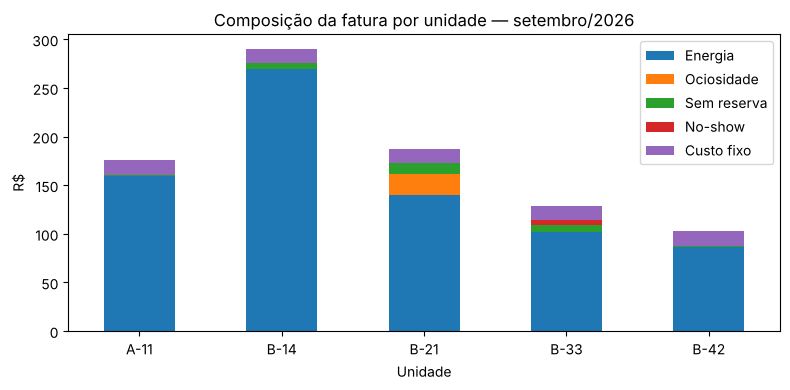

In [7]:
import matplotlib.pyplot as plt

componentes = {"custo_energia": "Energia", "ociosidade": "Ociosidade", "taxa_sem_agendamento": "Sem reserva",
               "no_show": "No-show", "custo_fixo": "Custo fixo"}
f = fatura.set_index("unidade_id")[list(componentes)].rename(columns=componentes)
ax = f.plot.bar(stacked=True, figsize=(8, 4), rot=0)
ax.set_ylabel("R$")
ax.set_xlabel("Unidade")
ax.set_title("Composição da fatura por unidade — setembro/2026")
plt.tight_layout()
plt.savefig(RAIZ / "evidencias" / "composicao_fatura.png", dpi=120)
plt.show()

## 4. Composição da fatura de um morador

O detalhe por sessão mostra de onde vem cada valor. Exemplo: unidade B-21 (Juliana Castro), total esperado de R$ 187,60.

In [8]:
detalhe = pd.read_csv(RAIZ / SAIDA / "detalhe_sessoes.csv", sep=";", decimal=",")
col_usuario = "usuario_id" if "usuario_id" in detalhe.columns else detalhe.columns[1]
juliana = detalhe[detalhe[col_usuario] == "U03"]
juliana

,sessao_id,usuario_id,agendamento_id,inicio,fim,duracao_min,kwh,custo_energia,ociosidade,taxa_sem_agendamento,no_show,total,observacao
1,S0002,U03,NaN,2026-09-01 23:30,2026-09-02 06:38,428.0,14.111,11.99,0.0,1.5,0.0,13.49,NaN
2,S0003,U03,AG0002,2026-09-03 21:09,2026-09-04 00:59,230.0,10.888,10.12,0.0,0.0,0.0,10.12,NaN
6,S0006,U03,AG0006,2026-09-05 19:30,2026-09-06 05:11,581.0,8.734,7.42,0.0,0.0,0.0,7.42,NaN
9,S0009,U03,AG0009,2026-09-09 21:18,2026-09-10 08:03,645.0,12.873,11.80,16.0,0.0,0.0,27.80,237 min parado com fila
12,S0012,U03,NaN,2026-09-11 19:40,2026-09-11 23:15,215.0,10.309,13.39,0.0,1.5,0.0,14.89,NaN
15,S0015,U03,NaN,2026-09-14 19:21,2026-09-15 02:48,447.0,18.007,21.33,0.0,1.5,0.0,22.83,NaN
18,S0018,U03,NaN,2026-09-16 20:35,2026-09-16 23:14,159.0,8.680,9.92,0.0,1.5,0.0,11.42,NaN
20,S0020,U03,AG0013,2026-09-18 19:13,2026-09-19 01:23,370.0,13.452,17.45,6.0,0.0,0.0,23.45,85 min parado com fila
24,S0024,U03,NaN,2026-09-21 18:22,2026-09-22 05:32,670.0,12.692,19.47,0.0,1.5,0.0,20.97,NaN
28,S0028,U03,NaN,2026-09-24 03:30,2026-09-24 07:14,224.0,10.696,9.09,0.0,1.5,0.0,10.59,NaN


In [9]:
total_detalhe = round(juliana["total"].sum(), 2)
linha = fatura[fatura["unidade_id"] == "B-21"].iloc[0]
print(f"Soma das sessões e no-shows: R$ {total_detalhe:.2f}")
print(f"Custo fixo da unidade:       R$ {linha['custo_fixo']:.2f}")
print(f"Total na fatura mensal:      R$ {linha['total']:.2f}")
assert abs(total_detalhe + linha["custo_fixo"] - linha["total"]) < 0.01

Soma das sessões e no-shows: R$ 172.60
Custo fixo da unidade:       R$ 15.00
Total na fatura mensal:      R$ 187.60


## 5. Módulo de IA: anomalias e previsão de uso

In [10]:
rodar("ia_uso.py", USO, SAIDA, 7)

$ python ia_uso.py evidencias/dados/uso evidencias/dados/saida 7 



Arquivos lidos: 5 | sessões analisadas: 34
Anomalias sinalizadas: 3
  Sessão S0006 | Usuário U03 | 05/09/2026 19:30
    Consumo: 8.734 kWh | Duração: 581 min
    Motivo: combinação de consumo, duração e potência diferente do padrão observado
  Sessão S0010 | Usuário U04 | 10/09/2026 08:06
    Consumo: 20.536 kWh | Duração: 200 min
    Motivo: sessão iniciada no fim ou após o término da reserva
  Sessão S0011 | Usuário U02 | 10/09/2026 11:29
    Consumo: 54.294 kWh | Duração: 702 min
    Motivo: combinação de consumo, duração e potência diferente do padrão observado

Previsão de consumo para os próximos 7 dias (estimativa em kWh):
      Data  Consumo previsto (kWh)
01/10/2026                  31.242
02/10/2026                  25.046
03/10/2026                  38.799
04/10/2026                  15.211
05/10/2026                  18.471
06/10/2026                  19.713
07/10/2026                  22.593

Relatório salvo em: evidencias/dados/saida/relatorio_ia.csv



In [11]:
relatorio = pd.read_csv(RAIZ / SAIDA / "relatorio_ia.csv", sep=";", encoding="utf-8-sig")
print(relatorio["tipo"].value_counts().to_string())
relatorio[relatorio["tipo"] == "previsao"] if (relatorio["tipo"] == "previsao").any() else relatorio.tail(7)

tipo
previsao            7
estatistica         2
fora_agendamento    1


,tipo,data,sessao_id,usuario_id,kwh,kwh_previsto,score_ia,metodo,observacao
3,previsao,2026-10-01,NaN,NaN,NaN,31.242,NaN,Previsão de consumo,"Estimativa, não é medição real."
4,previsao,2026-10-02,NaN,NaN,NaN,25.046,NaN,Previsão de consumo,"Estimativa, não é medição real."
5,previsao,2026-10-03,NaN,NaN,NaN,38.799,NaN,Previsão de consumo,"Estimativa, não é medição real."
6,previsao,2026-10-04,NaN,NaN,NaN,15.211,NaN,Previsão de consumo,"Estimativa, não é medição real."
7,previsao,2026-10-05,NaN,NaN,NaN,18.471,NaN,Previsão de consumo,"Estimativa, não é medição real."
8,previsao,2026-10-06,NaN,NaN,NaN,19.713,NaN,Previsão de consumo,"Estimativa, não é medição real."
9,previsao,2026-10-07,NaN,NaN,NaN,22.593,NaN,Previsão de consumo,"Estimativa, não é medição real."


## 6. Cenário com anomalias

O parâmetro `--anomalias` injeta problemas nos dados. O leitor, o rateio e a IA devem apontar os registros inválidos em vez de cobrá-los silenciosamente.

In [12]:
USO_ANOM, SAIDA_ANOM = DADOS / "uso_anomalias", DADOS / "saida_anomalias"
rodar("gerar_uso_carregador.py", "--seed", 5, "--anomalias", "--saida", USO_ANOM)
rodar("calcular_fatura.py", USO_ANOM, SAIDA_ANOM)
print((RAIZ / SAIDA_ANOM / "avisos.txt").read_text(encoding="utf-8"))

$ python gerar_uso_carregador.py --seed 5 --anomalias --saida evidencias/dados/uso_anomalias 

Arquivos gravados em: evidencias/dados/uso_anomalias
  uso_U01_ana_beatriz_souza.csv   115 linhas,  7 sessões, Ana Beatriz Souza (BYD Dolphin Mini)
  uso_U02_ricardo_mendes.csv   218 linhas,  6 sessões, Ricardo Mendes (BYD Dolphin Plus)
  uso_U03_juliana_castro.csv   270 linhas, 10 sessões, Juliana Castro (Híbrido plug-in)
  uso_U04_marcos_vinicius_rocha.csv    86 linhas,  6 sessões, Marcos Vinícius Rocha (BYD Dolphin Mini)
  uso_U05_patricia_nogueira.csv    85 linhas,  4 sessões, Patrícia Nogueira (BYD Dolphin)
  anomalia injetada: AG0008 (U01) criada com 20 min de antecedência (regra: 60 min)
  anomalia injetada: S0002 sem usuário/identificação (arquivo uso_NAO_IDENTIFICADO.csv)
  anomalia injetada: medidor saltou +3,2 kWh antes da sessão S0018 (consumo fora de sessão)
  total: 34 sessões, 774 kWh | semente 5 (repita com --seed 5)
  faixas normais de uso: OK

$ python calcular_fatura.py evi

Competência 2026-09: 6 arquivo(s) de uso lidos, 34 sessões reconstruídas

unid  usuário                  sess     kWh   energia  ocios.  s/res no-show   fixo     TOTAL
A-11  Ana Beatriz Souza           7   154.5    159,07    0,00   1,50    0,00  15,00    175,57
B-14  Ricardo Mendes              6   277.7    269,56    0,00   6,00    0,00  15,00    290,56
B-21  Juliana Castro             10   115.9    128,11   22,00   9,00    0,00  15,00    174,11
B-33  Marcos Vinícius Rocha       6   110.4    101,67    0,00   7,50    5,00  15,00    129,17
B-42  Patrícia Nogueira           4   101.5     86,30    0,00   1,50    0,00  15,00    102,80
                                                                  TOTAL A ARRECADAR  R$ 872,21
NAO_IDENTIFICADO: 1 sessão(ões), 14.11 kWh, R$ 11,99 pendentes
5 aviso(s) — ver evidencias/dados/saida_anomalias/avisos.txt
  aviso: AG0008: criada com menos de 60 min de antecedência
  aviso: S0018: medidor avançou 3.200 kWh desde a sessão S0017 (consumo fora de ses

In [13]:
rodar("ia_uso.py", USO_ANOM, SAIDA_ANOM, 7)

$ python ia_uso.py evidencias/dados/uso_anomalias evidencias/dados/saida_anomalias 7 



Arquivos lidos: 6 | sessões analisadas: 34
Anomalias sinalizadas: 5
  Sessão S0002 | Usuário NAO_IDENTIFICADO | 01/09/2026 23:30
    Consumo: 14.111 kWh | Duração: 428 min
    Motivo: sessão sem identificação completa
  Sessão S0006 | Usuário U03 | 05/09/2026 19:30
    Consumo: 8.734 kWh | Duração: 581 min
    Motivo: combinação de consumo, duração e potência diferente do padrão observado
  Sessão S0008 | Usuário U01 | 08/09/2026 19:37
    Consumo: 21.392 kWh | Duração: 204 min
    Motivo: reserva criada com menos de 60 minutos de antecedência
  Sessão S0010 | Usuário U04 | 10/09/2026 08:06
    Consumo: 20.536 kWh | Duração: 200 min
    Motivo: sessão iniciada no fim ou após o término da reserva
  Sessão S0011 | Usuário U02 | 10/09/2026 11:29
    Consumo: 54.294 kWh | Duração: 702 min
    Motivo: combinação de consumo, duração e potência diferente do padrão observado

Previsão de consumo para os próximos 7 dias (estimativa em kWh):
      Data  Consumo previsto (kWh)
01/10/2026         

## 7. Testes automatizados

In [14]:
rodar("-m", "unittest", "discover", "-s", "tests", "-v")

$ python -m unittest discover -s tests -v 



Duração máxima: 120 min.
Reserva só com 60 min de antecedência.
Reserva confirmada. No-show ou cancelamento com menos de 60 min: R$ 5,00.
Horário já reservado.
test_historico_curto_usa_fallback (test_ia_uso.TestIAUso.test_historico_curto_usa_fallback) ... ok
test_previsao_gera_dias_solicitados (test_ia_uso.TestIAUso.test_previsao_gera_dias_solicitados) ... ok
test_reserva_criada_com_menos_de_uma_hora_e_sinalizada (test_ia_uso.TestIAUso.test_reserva_criada_com_menos_de_uma_hora_e_sinalizada) ... ok
test_sem_sessoes_nao_quebra (test_ia_uso.TestIAUso.test_sem_sessoes_nao_quebra) ... ok
test_sessao_avulsa_normal_nao_e_anomalia (test_ia_uso.TestIAUso.test_sessao_avulsa_normal_nao_e_anomalia) ... ok
test_sessao_fora_da_janela_de_reserva_e_sinalizada (test_ia_uso.TestIAUso.test_sessao_fora_da_janela_de_reserva_e_sinalizada) ... ok
test_sessao_sem_identificacao_e_sinalizada (test_ia_uso.TestIAUso.test_sessao_sem_identificacao_e_sinalizada) ... ok
test_soc_acima_de_100_e_sinalizado (test_ia_uso